# Лабораторная работа № 7

## Решение задачи классификации методом решающих деревьев и ансамблей на их основе

**Цель работы:** научиться решать задачу классификации методами решающих деревьев и ансамблей на их основе (бэггинг, бустинг, Random Forest).

Используется набор данных `employees_4.csv` вариант 14 – «Сотрудники компании»

Признаки:
- **Education** – уровень образования (Bachelors, Masters, PHD)
- **JoiningYear** – год приёма на работу
- **City** – город, в котором расположен офис (Bangalore, Pune, New Delhi)
- **PaymentTier** – уровень оплаты (1 – высший, 3 – низший)
- **Age** – возраст
- **Gender** – пол
- **EverBenched** – находился ли сотрудник «на скамейке» (без проектов) в течение месяца и более
- **ExperienceInCurrentDomain** – опыт работы в текущей области, лет
- **LeaveOrNot** – целевая переменная: 1 – сотрудник ушёл, 0 – остался

## 1. Импорт необходимых библиотек

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_curve, roc_auc_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Загрузка и первичный анализ данных

In [2]:
df = pd.read_csv('employees_4.csv')
print("Размер датафрейма:", df.shape)
df.head()

Размер датафрейма: (4653, 9)


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1


### 2.1. Общее представление о наборе данных: shape, head, describe, info

In [3]:
df.shape

(4653, 9)

In [4]:
df.head(10)

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
0,Bachelors,2017,Bangalore,3,34,Male,No,0,0
1,Bachelors,2013,Pune,1,28,Female,No,3,1
2,Bachelors,2014,New Delhi,3,38,Female,No,2,0
3,Masters,2016,Bangalore,3,27,Male,No,5,1
4,Masters,2017,Pune,3,24,Male,Yes,2,1
5,Bachelors,2016,Bangalore,3,22,Male,No,0,0
6,Bachelors,2015,New Delhi,3,38,Male,No,0,0
7,Bachelors,2016,Bangalore,3,34,Female,No,2,1
8,Bachelors,2016,Pune,3,23,Male,No,1,0
9,Masters,2017,New Delhi,2,37,Male,No,2,0


In [5]:
df.describe()

,JoiningYear,PaymentTier,Age,ExperienceInCurrentDomain,LeaveOrNot
count,4653.000000,4653.000000,4653.000000,4653.000000,4653.000000
mean,2015.062970,2.698259,29.393295,2.905652,0.343864
std,1.863377,0.561435,4.826087,1.558240,0.475047
min,2012.000000,1.000000,22.000000,0.000000,0.000000
25%,2013.000000,3.000000,26.000000,2.000000,0.000000
50%,2015.000000,3.000000,28.000000,3.000000,0.000000
75%,2017.000000,3.000000,32.000000,4.000000,1.000000
max,2018.000000,3.000000,41.000000,7.000000,1.000000


In [6]:
df.describe(include='object')

,Education,City,Gender,EverBenched
count,4653,4653,4653,4653
unique,3,3,2,2
top,Bachelors,Bangalore,Male,No
freq,3601,2228,2778,4175


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4653 entries, 0 to 4652
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Education                  4653 non-null   str  
 1   JoiningYear                4653 non-null   int64
 2   City                       4653 non-null   str  
 3   PaymentTier                4653 non-null   int64
 4   Age                        4653 non-null   int64
 5   Gender                     4653 non-null   str  
 6   EverBenched                4653 non-null   str  
 7   ExperienceInCurrentDomain  4653 non-null   int64
 8   LeaveOrNot                 4653 non-null   int64
dtypes: int64(5), str(4)
memory usage: 327.3 KB


## 3. Проверка пропусков и баланса классов

Пропущенные значения по столбцам:
Education                    0
JoiningYear                  0
City                         0
PaymentTier                  0
Age                          0
Gender                       0
EverBenched                  0
ExperienceInCurrentDomain    0
LeaveOrNot                   0
dtype: int64

Баланс классов целевой переменной (LeaveOrNot):
LeaveOrNot
0    3053
1    1600
Name: count, dtype: int64
LeaveOrNot
0    0.6561
1    0.3439
Name: proportion, dtype: float64


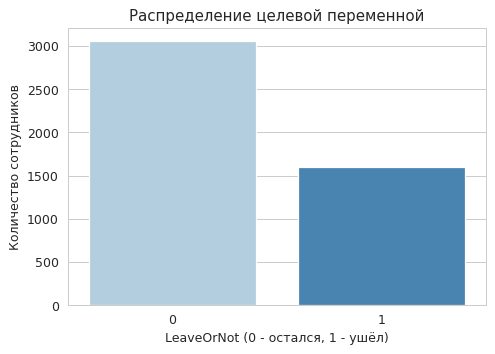

In [8]:
print("Пропущенные значения по столбцам:")
print(df.isna().sum())
print("\nБаланс классов целевой переменной (LeaveOrNot):")
print(df['LeaveOrNot'].value_counts())
print(df['LeaveOrNot'].value_counts(normalize=True).round(4))

plt.figure(figsize=(6, 4))
sns.countplot(x='LeaveOrNot', data=df, palette='Blues')
plt.title('Распределение целевой переменной')
plt.xlabel('LeaveOrNot (0 - остался, 1 - ушёл)')
plt.ylabel('Количество сотрудников')
plt.show()

Пропусков в данных нет. Классы не сбалансированы: примерно 66 % сотрудников остались и 34 % ушли, поэтому наряду с accuracy будем смотреть precision, recall, F1 и ROC-AUC.

## 4. Разделение данных на обучающую и тестовую выборки

Разделение выполняем **до** кодирования и нормализации: параметры предобработки считаем только по обучающей выборке, чтобы информация из тестовой выборки не попадала в модель (утечка данных). Используем стратификацию по целевой переменной.

In [9]:
cat_cols = ['Education', 'City', 'Gender', 'EverBenched']
num_cols = ['JoiningYear', 'PaymentTier', 'Age', 'ExperienceInCurrentDomain']

X = df.drop(columns=['LeaveOrNot'])
y = df['LeaveOrNot']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Обучающая выборка: {X_train.shape[0]} samples")
print(f"Тестовая выборка: {X_test.shape[0]} samples")
print("Доля класса «ушёл» в train: %.4f, в test: %.4f" % (y_train.mean(), y_test.mean()))

Обучающая выборка: 3722 samples
Тестовая выборка: 931 samples
Доля класса «ушёл» в train: 0.3439, в test: 0.3437


## 5. Предобработка данных

### 5.1. Кодирование категориальных признаков в дискретные величины с помощью методов библиотеки sklearn

In [10]:
# Для Education задаём естественный порядок уровней, для остальных - порядок по алфавиту
encoder = OrdinalEncoder(categories=[['Bachelors', 'Masters', 'PHD'],
                                     sorted(X_train['City'].unique()),
                                     sorted(X_train['Gender'].unique()),
                                     sorted(X_train['EverBenched'].unique())])

X_train_enc = X_train.copy()
X_test_enc = X_test.copy()
X_train_enc[cat_cols] = encoder.fit_transform(X_train[cat_cols]).astype(int)
X_test_enc[cat_cols] = encoder.transform(X_test[cat_cols]).astype(int)

for name, cats in zip(cat_cols, encoder.categories_):
    print(name, '->', {c: i for i, c in enumerate(cats)})
X_train_enc.head()

Education -> {'Bachelors': 0, 'Masters': 1, 'PHD': 2}
City -> {'Bangalore': 0, 'New Delhi': 1, 'Pune': 2}
Gender -> {'Female': 0, 'Male': 1}
EverBenched -> {'No': 0, 'Yes': 1}


,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain
4097,0,2012,1,3,38,0,0,1
1694,0,2018,0,3,26,1,0,4
2659,0,2016,2,3,27,1,0,5
3860,0,2016,0,3,36,1,0,4
1250,0,2017,0,3,27,1,1,5


### 5.2. Нормализация данных с помощью методов библиотеки sklearn

In [11]:
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train_enc), columns=X.columns, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test_enc), columns=X.columns, index=X_test.index)
X_train_sc.head()

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain
4097,-0.508343,-1.660210,0.263699,0.536275,1.787302,-1.233564,-0.334228,-1.230717
1694,-0.508343,1.559295,-0.928873,0.536275,-0.697541,0.810659,-0.334228,0.696658
2659,-0.508343,0.486126,1.456271,0.536275,-0.490470,0.810659,-0.334228,1.339116
3860,-0.508343,0.486126,-0.928873,0.536275,1.373162,0.810659,-0.334228,0.696658
1250,-0.508343,1.022710,-0.928873,0.536275,-0.490470,0.810659,2.991968,1.339116


Деревья решений и ансамбли на их основе работают с порогами по отдельным признакам и **инвариантны к масштабу признаков**, поэтому нормализация не влияет на их качество, но этот этап предусмотрен заданием. Дальше все модели обучаются на нормализованных данных `X_train_sc` (пороги в узлах деревьев при этом выражены в нормализованных единицах).

## 6. Построение и оценка базового дерева решений

In [12]:
base_dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
base_dt.fit(X_train_sc, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

In [13]:
y_pred_base = base_dt.predict(X_test_sc)
accuracy_base = accuracy_score(y_test, y_pred_base)
print(f"Точность базового дерева на тесте: {accuracy_base:.4f}")
print(f"Глубина дерева: {base_dt.get_depth()}, число листьев: {base_dt.get_n_leaves()}")

Точность базового дерева на тесте: 0.8024
Глубина дерева: 21, число листьев: 730


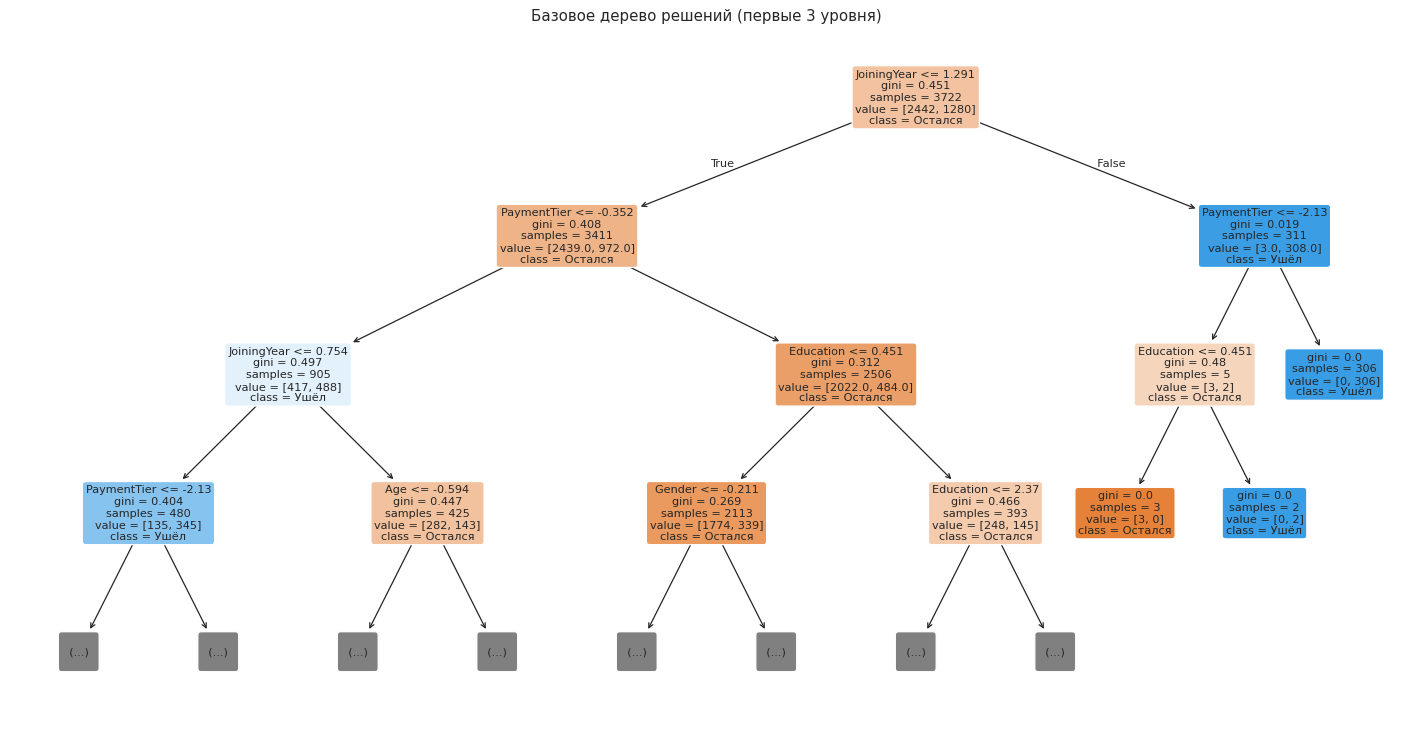

In [14]:
plt.figure(figsize=(20, 10))
plot_tree(base_dt, filled=True, feature_names=X.columns.tolist(), class_names=['Остался', 'Ушёл'],
          rounded=True, max_depth=3, fontsize=9)
plt.title("Базовое дерево решений (первые 3 уровня)")
plt.show()

## 7. Борьба с переобучением: настройка гиперпараметров дерева

In [15]:
tuned_dt = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tuned_dt.fit(X_train_sc, y_train)

y_pred_tuned = tuned_dt.predict(X_test_sc)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print(f"Точность настроенного дерева (max_depth=3) на тесте: {accuracy_tuned:.4f}")

Точность настроенного дерева (max_depth=3) на тесте: 0.7723


In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores_base = cross_val_score(base_dt, X_train_sc, y_train, cv=cv)
cv_scores_tuned = cross_val_score(tuned_dt, X_train_sc, y_train, cv=cv)

print(f"Кросс-валидация, базовое дерево: {np.mean(cv_scores_base):.4f} (+/- {np.std(cv_scores_base) * 2:.4f})")
print(f"Кросс-валидация, настроенное дерево: {np.mean(cv_scores_tuned):.4f} (+/- {np.std(cv_scores_tuned) * 2:.4f})")

Кросс-валидация, базовое дерево: 0.8004 (+/- 0.0288)
Кросс-валидация, настроенное дерево: 0.7953 (+/- 0.0167)


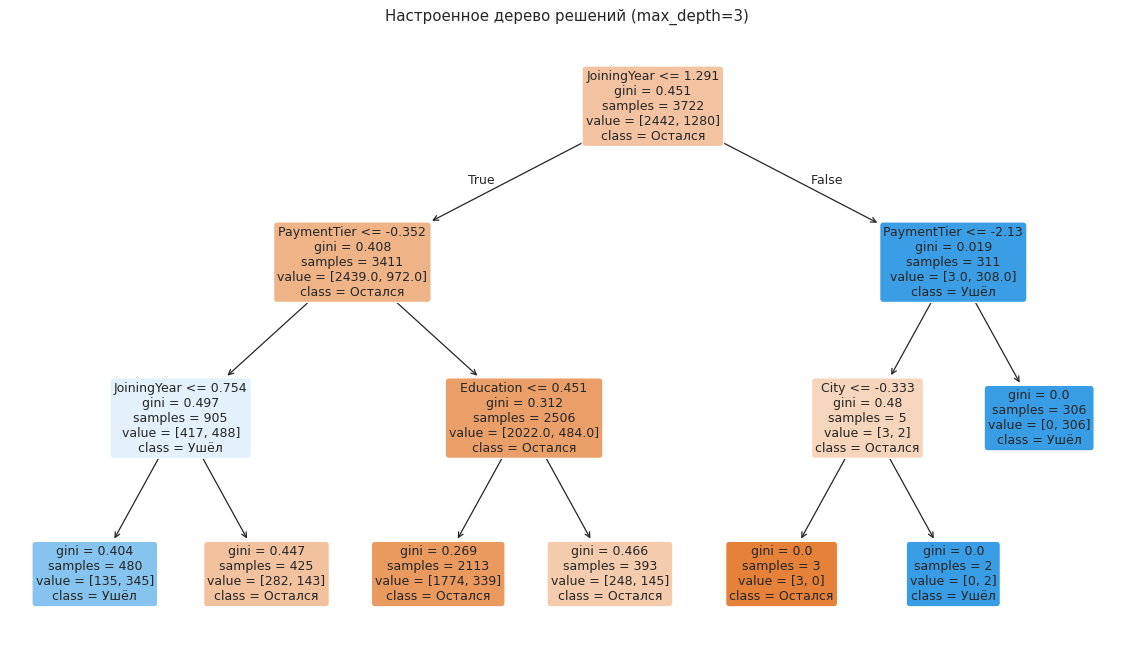

In [17]:
plt.figure(figsize=(16, 9))
plot_tree(tuned_dt, filled=True, feature_names=X.columns.tolist(), class_names=['Остался', 'Ушёл'],
          rounded=True, fontsize=10)
plt.title("Настроенное дерево решений (max_depth=3)")
plt.show()

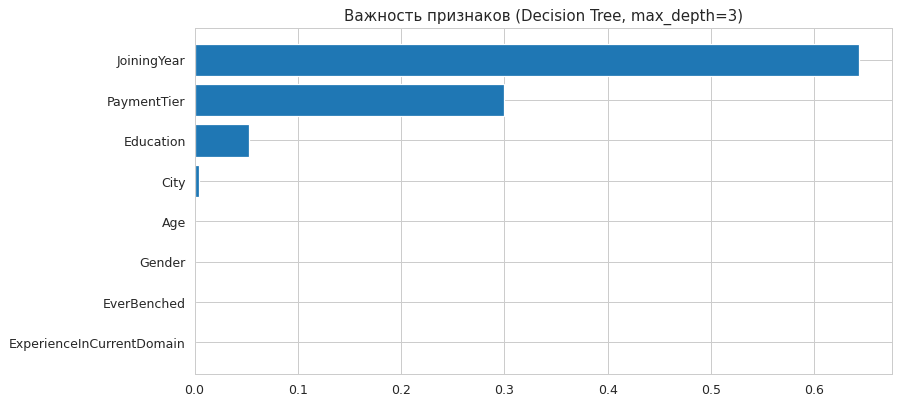

In [18]:
importances = tuned_dt.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10, 5))
plt.title("Важность признаков (Decision Tree, max_depth=3)")
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.gca().invert_yaxis()
plt.show()

## 8. Ансамбли: Случайный лес (Random Forest, бэггинг)

Random Forest строит множество деревьев на бутстреп-выборках, при каждом разбиении рассматривая случайное подмножество признаков; итоговый класс определяется голосованием деревьев. Это снижает дисперсию и переобучение по сравнению с одиночным деревом.

In [19]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
rf_model.fit(X_train_sc, y_train)
print("Модель Random Forest обучена!")

Модель Random Forest обучена!


### 8.1. Прогнозирование и оценка модели

In [20]:
y_pred_rf = rf_model.predict(X_test_sc)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Точность Random Forest на тестовой выборке: {accuracy_rf:.4f}")

print("\n" + "=" * 50)
print("Отчет по классификации:")
print("=" * 50)
print(classification_report(y_test, y_pred_rf, target_names=['stay (0)', 'leave (1)']))

Точность Random Forest на тестовой выборке: 0.8303

Отчет по классификации:
              precision    recall  f1-score   support

    stay (0)       0.84      0.92      0.88       611
   leave (1)       0.82      0.65      0.73       320

    accuracy                           0.83       931
   macro avg       0.83      0.79      0.80       931
weighted avg       0.83      0.83      0.83       931



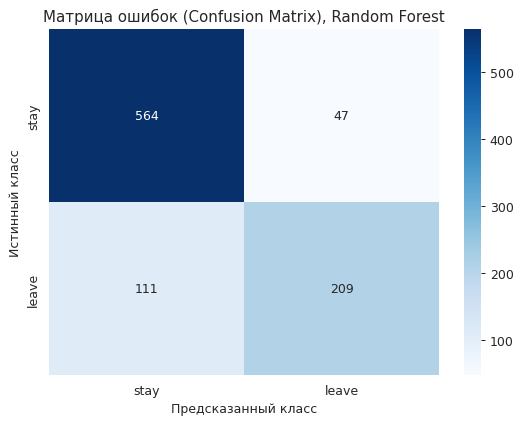

In [21]:
plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['stay', 'leave'], yticklabels=['stay', 'leave'])
plt.title('Матрица ошибок (Confusion Matrix), Random Forest')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

### 8.2. Анализ важности признаков

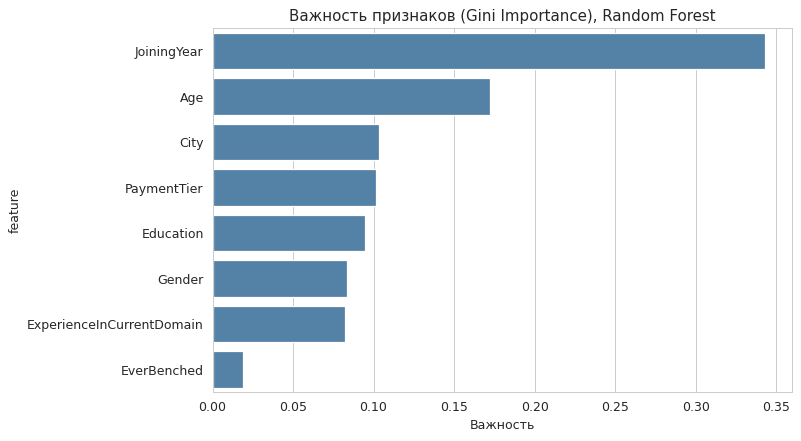

,feature,importance
1,JoiningYear,0.342957
4,Age,0.172082
2,City,0.103190
3,PaymentTier,0.101620
0,Education,0.094790
5,Gender,0.083704
7,ExperienceInCurrentDomain,0.082465
6,EverBenched,0.019192


In [22]:
features_df = pd.DataFrame({'feature': X.columns, 'importance': rf_model.feature_importances_})
features_df = features_df.sort_values('importance', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x='importance', y='feature', data=features_df, color='steelblue')
plt.title('Важность признаков (Gini Importance), Random Forest')
plt.xlabel('Важность')
plt.tight_layout()
plt.show()

features_df

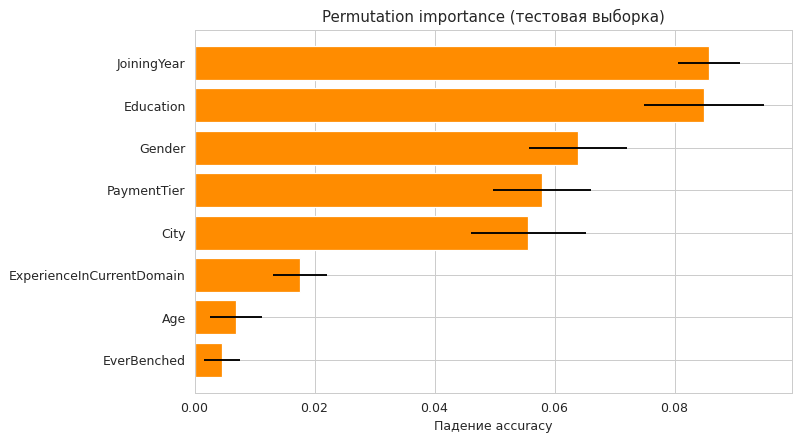

,feature,importance_mean,importance_std
1,JoiningYear,0.085714,0.005124
0,Education,0.084855,0.009972
5,Gender,0.063910,0.008226
3,PaymentTier,0.057895,0.008201
2,City,0.055639,0.009593
7,ExperienceInCurrentDomain,0.017615,0.004460
4,Age,0.006874,0.004302
6,EverBenched,0.004619,0.002963


In [23]:
# Permutation importance на тестовой выборке: падение accuracy при перемешивании признака
perm = permutation_importance(rf_model, X_test_sc, y_test, n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_df = pd.DataFrame({'feature': X.columns, 'importance_mean': perm.importances_mean,
                        'importance_std': perm.importances_std}).sort_values('importance_mean', ascending=False)

plt.figure(figsize=(9, 5))
plt.barh(perm_df['feature'], perm_df['importance_mean'], xerr=perm_df['importance_std'], color='darkorange')
plt.gca().invert_yaxis()
plt.title('Permutation importance (тестовая выборка)')
plt.xlabel('Падение accuracy')
plt.tight_layout()
plt.show()

perm_df

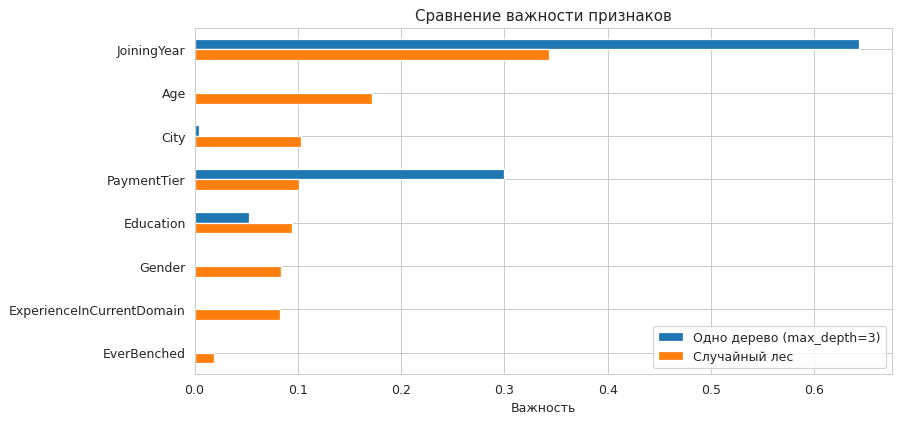

In [24]:
# Сравнение важности признаков одиночного дерева и случайного леса
imp_cmp = pd.DataFrame({'Одно дерево (max_depth=3)': tuned_dt.feature_importances_,
                        'Случайный лес': rf_model.feature_importances_}, index=X.columns)
imp_cmp.sort_values('Случайный лес', ascending=False).plot(kind='barh', figsize=(10, 5))
plt.gca().invert_yaxis()
plt.title('Сравнение важности признаков')
plt.xlabel('Важность')
plt.show()

## 9. Подбор гиперпараметров Random Forest (GridSearchCV)

Подбор выполняется перебором по сетке с 5-кратной кросс-валидацией на обучающей выборке; тестовая выборка в подборе не участвует.

In [25]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
print("Число комбинаций параметров:", np.prod([len(v) for v in param_grid.values()]))

rf_search = RandomForestClassifier(random_state=RANDOM_STATE)
grid_search = GridSearchCV(estimator=rf_search, param_grid=param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_sc, y_train)

Число комбинаций параметров: 72


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computat

In [26]:
print("Лучшие параметры:", grid_search.best_params_)
print("Лучшая точность при кросс-валидации: {:.4f}".format(grid_search.best_score_))

best_rf_model = grid_search.best_estimator_
y_pred_best = best_rf_model.predict(X_test_sc)
best_accuracy = accuracy_score(y_test, y_pred_best)
print(f"Точность улучшенной модели на тестовой выборке: {best_accuracy:.4f}")
print(f"Точность исходного Random Forest на тестовой выборке: {accuracy_rf:.4f}")

Лучшие параметры: {'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}
Лучшая точность при кросс-валидации: 0.8469
Точность улучшенной модели на тестовой выборке: 0.8528
Точность исходного Random Forest на тестовой выборке: 0.8303


              precision    recall  f1-score   support

    stay (0)       0.84      0.96      0.90       611
   leave (1)       0.90      0.64      0.75       320

    accuracy                           0.85       931
   macro avg       0.87      0.80      0.82       931
weighted avg       0.86      0.85      0.85       931



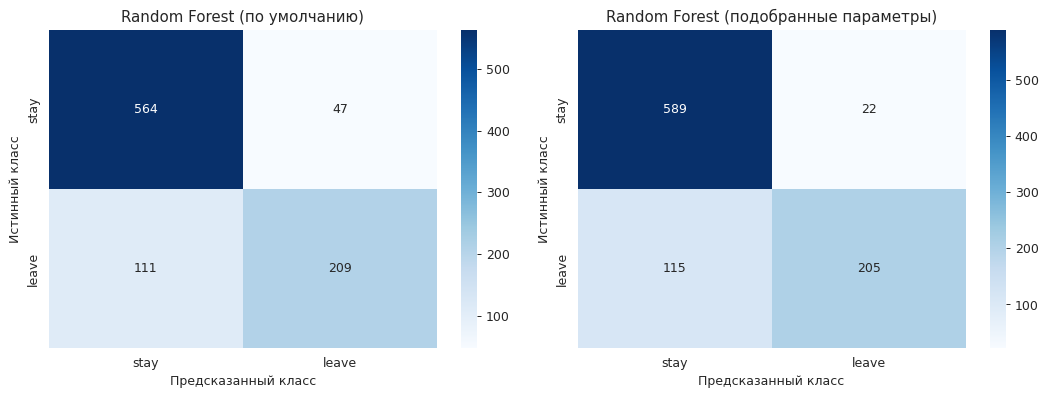

In [27]:
print(classification_report(y_test, y_pred_best, target_names=['stay (0)', 'leave (1)']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, pred, title in zip(axes, [y_pred_rf, y_pred_best], ['Random Forest (по умолчанию)', 'Random Forest (подобранные параметры)']):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['stay', 'leave'], yticklabels=['stay', 'leave'])
    ax.set_title(title)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

In [28]:
# Топ-10 комбинаций параметров по результатам кросс-валидации
res = pd.DataFrame(grid_search.cv_results_)
res[['param_n_estimators', 'param_max_depth', 'param_min_samples_split', 'param_min_samples_leaf',
     'mean_test_score', 'std_test_score']].sort_values('mean_test_score', ascending=False).head(10)

,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,mean_test_score,std_test_score
17,200,None,10,4,0.846853,0.007084
65,200,15,10,2,0.846586,0.004973
70,100,15,10,4,0.846585,0.006659
64,100,15,10,2,0.846316,0.006803
53,200,10,10,4,0.845779,0.005535
42,100,10,2,2,0.845241,0.006168
39,200,10,5,1,0.845241,0.007051
49,200,10,2,4,0.844973,0.006524
51,200,10,5,4,0.844973,0.006524
38,100,10,5,1,0.844972,0.007846


## 10. Ансамбли: бустинг (Boosting)

В бустинге деревья строятся **последовательно**: каждое следующее исправляет ошибки предыдущих. Рассмотрим `GradientBoostingClassifier` и `AdaBoostClassifier`.

In [29]:
gb = GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
gb.fit(X_train_sc, y_train)
print(f"Точность Gradient Boosting на тесте: {accuracy_score(y_test, gb.predict(X_test_sc)):.4f}")

ada = AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE)
ada.fit(X_train_sc, y_train)
print(f"Точность AdaBoost на тесте: {accuracy_score(y_test, ada.predict(X_test_sc)):.4f}")

Точность Gradient Boosting на тесте: 0.8528
Точность AdaBoost на тесте: 0.7916


## 11. Сравнение всех моделей

In [30]:
models = {
    'Base Decision Tree': base_dt,
    'Tuned Decision Tree (depth=3)': tuned_dt,
    'Random Forest': rf_model,
    'Random Forest (GridSearchCV)': best_rf_model,
    'Gradient Boosting': gb,
    'AdaBoost': ada,
}
results = {}
for name, model in models.items():
    proba = model.predict_proba(X_test_sc)[:, 1]
    pred = model.predict(X_test_sc)
    results[name] = {
        'Train Accuracy': accuracy_score(y_train, model.predict(X_train_sc)),
        'Test Accuracy': accuracy_score(y_test, pred),
        'Test ROC-AUC': roc_auc_score(y_test, proba),
    }
results_df = pd.DataFrame(results).T
results_df.round(4)

,Train Accuracy,Test Accuracy,Test ROC-AUC
Base Decision Tree,0.9296,0.8024,0.7903
Tuned Decision Tree (depth=3),0.7953,0.7723,0.7680
Random Forest,0.9296,0.8303,0.8561
Random Forest (GridSearchCV),0.8713,0.8528,0.8814
Gradient Boosting,0.8520,0.8528,0.8833
AdaBoost,0.8015,0.7916,0.8222


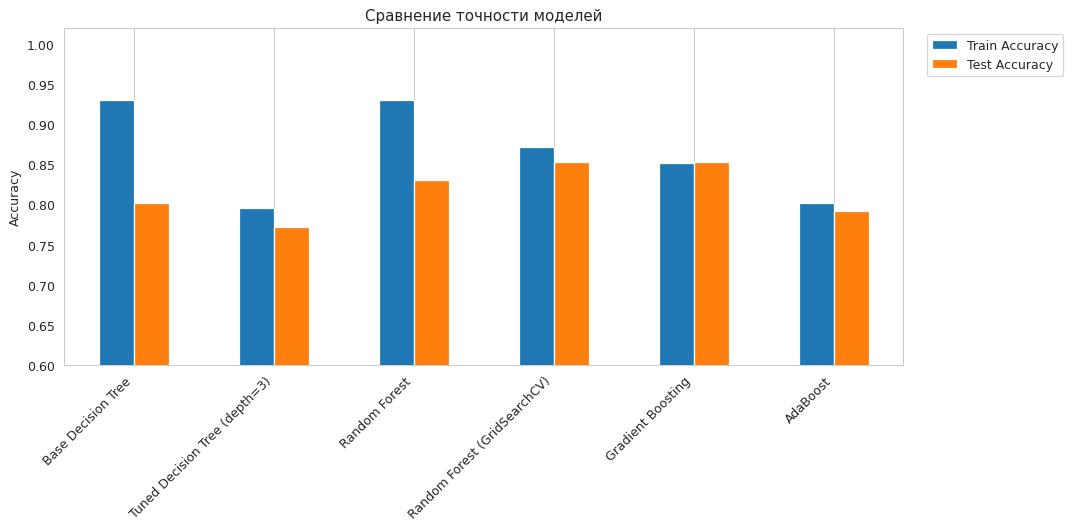

In [31]:
results_df[['Train Accuracy', 'Test Accuracy']].plot(kind='bar', figsize=(12, 6))
plt.title("Сравнение точности моделей")
plt.ylabel("Accuracy")
plt.ylim(0.6, 1.02)
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

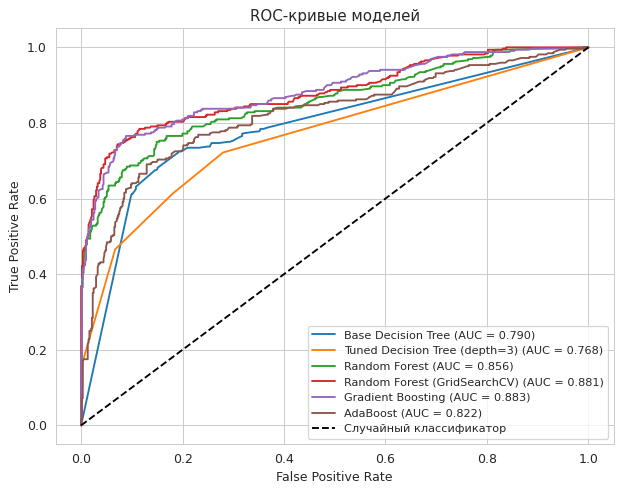

In [32]:
plt.figure(figsize=(8, 6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test_sc)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['Test ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend(loc='lower right', fontsize=9)
plt.show()

## 12. Дополнительные исследования (задания для самостоятельной работы)

### 12.1. Глубокая настройка одиночного дерева (GridSearchCV)

In [33]:
tree_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, 12, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'criterion': ['gini', 'entropy']
}
tree_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), tree_grid,
                           cv=cv, scoring='accuracy', n_jobs=-1)
tree_search.fit(X_train_sc, y_train)

best_dt = tree_search.best_estimator_
print("Лучшие параметры дерева:", tree_search.best_params_)
print("Точность при кросс-валидации: {:.4f}".format(tree_search.best_score_))
print(f"Точность на тесте: подобранное дерево {accuracy_score(y_test, best_dt.predict(X_test_sc)):.4f}, "
      f"базовое дерево {accuracy_base:.4f}, дерево max_depth=3 {accuracy_tuned:.4f}")

Лучшие параметры дерева: {'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 2, 'min_samples_split': 20}
Точность при кросс-валидации: 0.8396
Точность на тесте: подобранное дерево 0.8432, базовое дерево 0.8024, дерево max_depth=3 0.7723


### 12.2. Зависимость точности от количества деревьев

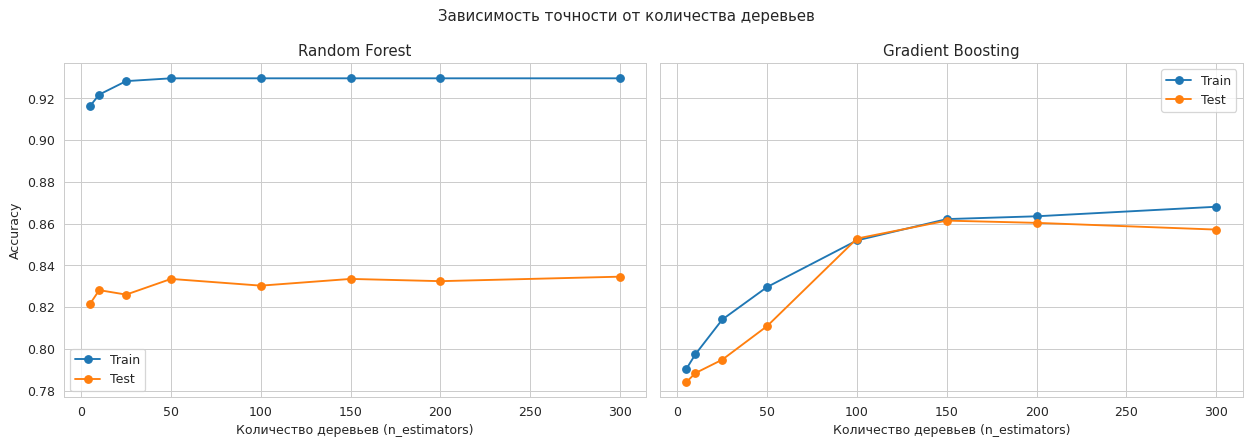

,n_estimators,RF test,GB test
0,5,0.8217,0.7841
1,10,0.8281,0.7884
2,25,0.8260,0.7948
3,50,0.8335,0.8110
4,100,0.8303,0.8528
5,150,0.8335,0.8614
6,200,0.8324,0.8604
7,300,0.8346,0.8571


In [34]:
n_list = [5, 10, 25, 50, 100, 150, 200, 300]
rf_train, rf_test, gb_train, gb_test = [], [], [], []
for n in n_list:
    m = RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE).fit(X_train_sc, y_train)
    rf_train.append(accuracy_score(y_train, m.predict(X_train_sc)))
    rf_test.append(accuracy_score(y_test, m.predict(X_test_sc)))
    m = GradientBoostingClassifier(n_estimators=n, random_state=RANDOM_STATE).fit(X_train_sc, y_train)
    gb_train.append(accuracy_score(y_train, m.predict(X_train_sc)))
    gb_test.append(accuracy_score(y_test, m.predict(X_test_sc)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].plot(n_list, rf_train, marker='o', label='Train')
axes[0].plot(n_list, rf_test, marker='o', label='Test')
axes[0].set_title('Random Forest')
axes[1].plot(n_list, gb_train, marker='o', label='Train')
axes[1].plot(n_list, gb_test, marker='o', label='Test')
axes[1].set_title('Gradient Boosting')
for ax in axes:
    ax.set_xlabel('Количество деревьев (n_estimators)')
    ax.legend()
axes[0].set_ylabel('Accuracy')
plt.suptitle('Зависимость точности от количества деревьев')
plt.tight_layout()
plt.show()

pd.DataFrame({'n_estimators': n_list, 'RF test': rf_test, 'GB test': gb_test}).round(4)

### 12.3. Анализ переобучения одиночного дерева

Лучшая глубина по тесту: 8, accuracy = 0.8453


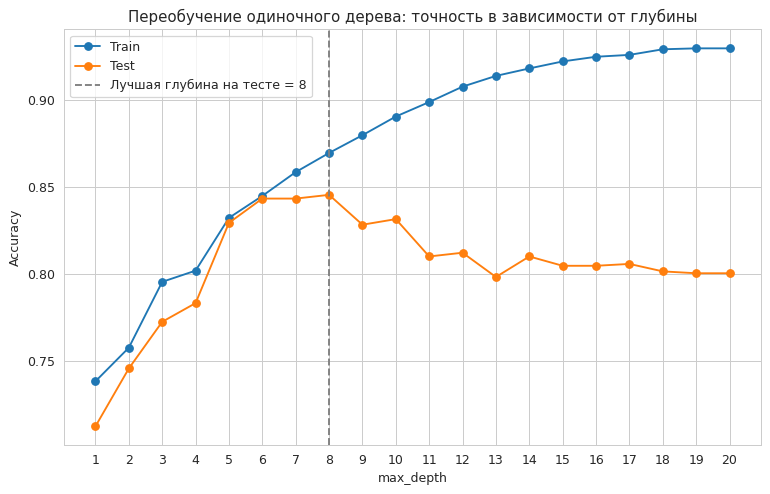

In [35]:
depths = list(range(1, 21))
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train_sc, y_train)
    tr.append(accuracy_score(y_train, m.predict(X_train_sc)))
    te.append(accuracy_score(y_test, m.predict(X_test_sc)))

best_d = depths[int(np.argmax(te))]
plt.figure(figsize=(10, 6))
plt.plot(depths, tr, marker='o', label='Train')
plt.plot(depths, te, marker='o', label='Test')
plt.axvline(best_d, color='gray', linestyle='--', label=f'Лучшая глубина на тесте = {best_d}')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Переобучение одиночного дерева: точность в зависимости от глубины')
plt.xticks(depths)
plt.legend()
plt.show()

print(f"Лучшая глубина по тесту: {best_d}, accuracy = {max(te):.4f}")

## 13. Выводы

В работе решалась задача бинарной классификации: по данным о сотруднике (4653 наблюдения, 8 признаков) предсказывалось, уйдёт ли он из компании. Пропусков в данных нет. Категориальные признаки закодированы `OrdinalEncoder`, числовые нормализованы `StandardScaler`; разделение на обучающую (80 %) и тестовую (20 %) выборки выполнено со стратификацией до предобработки, чтобы не допустить утечки данных. Классы не сбалансированы (около 34 % ушедших), поэтому наряду с accuracy использовался ROC-AUC.

Результаты на тестовой выборке:

| Модель | Train Accuracy | Test Accuracy | ROC-AUC |
|---|---|---|---|
| Дерево без ограничений | 0.9296 | 0.8024 | 0.7903 |
| Дерево (max_depth=3) | 0.7953 | 0.7723 | 0.7680 |
| Random Forest | 0.9296 | 0.8303 | 0.8561 |
| Random Forest (GridSearchCV) | 0.8713 | 0.8528 | 0.8814 |
| Gradient Boosting | 0.8520 | 0.8528 | 0.8833 |
| AdaBoost | 0.8015 | 0.7916 | 0.8222 |

1. **Одиночное дерево.** Дерево без ограничений переобучается: на обучающей выборке accuracy 0.930, на тесте 0.802 (глубина 21, 730 листьев). Ограничение глубины до 3, в отличие от примера с раком груди, ухудшает результат (0.772): трёх уровней недостаточно, чтобы описать зависимость в данных. По графику в разделе 12.3 лучшая глубина около 8 (accuracy на тесте 0.845); GridSearchCV в разделе 12.1 тоже выбрал глубину 8 (0.843 на тесте).
2. **Random Forest.** Лес из 100 деревьев (0.830) лучше одиночного дерева (0.802), так как усреднение множества деревьев снижает дисперсию. После подбора гиперпараметров (`n_estimators=200`, `min_samples_leaf=4`, `min_samples_split=10`, глубина без ограничения) accuracy выросла до 0.853, ROC-AUC – до 0.881; train accuracy при этом снизилась с 0.930 до 0.871, то есть переобучение уменьшилось.
3. **Бустинг.** Gradient Boosting (0.853) сравнялся с подобранным лесом и имеет чуть лучший ROC-AUC, AdaBoost (0.792) слабее остальных ансамблей. По графику в разделе 12.2 точность леса выходит на плато уже при 50 деревьях, а градиентный бустинг растёт примерно до 150 деревьев.
4. **Важность признаков.** Самый важный признак – `JoiningYear` (по Gini-важности 0.34, по permutation importance тоже первое место). Далее по permutation importance идут `Education`, `Gender`, `PaymentTier` и `City`, а `Age`, получивший высокую Gini-важность, на тесте почти ничего не даёт; наименее важен `EverBenched`.
5. **Итог.** Лучшие результаты показали Random Forest с подобранными гиперпараметрами и Gradient Boosting (accuracy 0.853, ROC-AUC около 0.88). Ансамбли заметно надёжнее одиночного дерева, а подбор гиперпараметров снижает переобучение. Слабое место моделей – полнота по классу «ушёл» (0.65 у леса по умолчанию): уходящие сотрудники пропускаются чаще, чем остающиеся.